In [1]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

# Resources required for NLP tasks [cite: 8]
nltk.download('stopwords')
nltk.download('punkt')

# Configuration for reproducibility 
RANDOM_SEED = 42

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\trbha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\trbha\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [2]:
# Load the CSV file provided in the coursework 
df = pd.read_csv("cw_data.csv", header=None)
df.columns = ["text", "label"]

# Verify class distribution for the report 
print(df['label'].value_counts())
df.head()

label
payment_issue              33
shipping_delay             29
notification_settings      24
delete_account             23
subscription_management    23
update_email               23
data_privacy               22
order_tracking             22
billing_history            21
account_recovery           21
refund_request             21
reset_password             20
login_issue                16
two_factor_auth            10
Name: count, dtype: int64


,text,label
0,tracking shows shipped but no delivery help pls,shipping_delay
1,partial shipments tracked separately?,order_tracking
2,invalid email entered wat happens?,update_email
3,recover acct if suspended?,account_recovery
4,emial update failed error — fix?,update_email


In [3]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text_p1(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    words = text.split()
    words = [stemmer.stem(w) for w in words if w not in stop_words]
    return " ".join(words)

# Apply pre-processing to the raw text
df['clean_text'] = df['text'].apply(clean_text_p1)

In [4]:
# Stratify is recommended for imbalanced datasets 
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], 
    df['label'], 
    test_size=0.2, 
    random_state=RANDOM_SEED,
    stratify=df['label']
)

In [5]:
# Baseline encoding using single words (Unigrams) 
vectorizer = TfidfVectorizer(ngram_range=(1,1))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [6]:
# Using 'balanced' weights to handle class imbalance
model = LogisticRegression(
    max_iter=1000, 
    class_weight='balanced', 
    random_state=RANDOM_SEED
)

model.fit(X_train_vec, y_train)

# Generate predictions for evaluation
y_pred = model.predict(X_test_vec)

--- Pipeline 1 Classification Report ---
                         precision    recall  f1-score   support

       account_recovery       0.80      1.00      0.89         4
        billing_history       1.00      0.75      0.86         4
           data_privacy       1.00      0.50      0.67         4
         delete_account       0.83      1.00      0.91         5
            login_issue       1.00      1.00      1.00         3
  notification_settings       1.00      1.00      1.00         5
         order_tracking       0.75      0.75      0.75         4
          payment_issue       1.00      0.86      0.92         7
         refund_request       0.75      0.75      0.75         4
         reset_password       1.00      1.00      1.00         4
         shipping_delay       0.86      1.00      0.92         6
subscription_management       0.71      1.00      0.83         5
        two_factor_auth       1.00      0.50      0.67         2
           update_email       1.00      1.00    

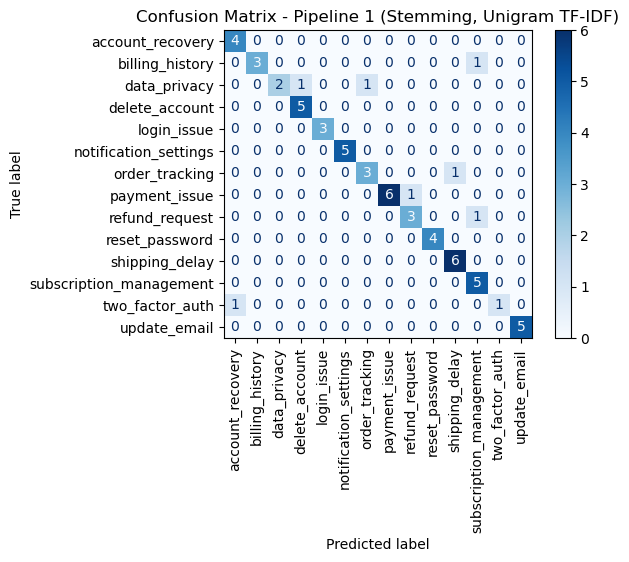

Macro F1 Score: 0.8691387977102263


In [7]:
# Focus on Macro-F1 for imbalanced support classes 
print("--- Pipeline 1 Classification Report ---")
print(classification_report(y_test, y_pred))

# Plot confusion matrix for qualitative analysis 
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=90, cmap='Blues')
plt.title("Confusion Matrix - Pipeline 1 (Stemming, Unigram TF-IDF)")
plt.show()


f1 = f1_score(y_test, y_pred, average='macro')
print("Macro F1 Score:", f1)

In [8]:
# Identify indices where the model failed [cite: 28]
error_mask = y_test != y_pred
error_indices = y_test[error_mask].index

print("--- Qualitative Analysis: Sample Errors ---")
for i in range(min(3, len(error_indices))):
    idx = error_indices[i]
    print(f"Original Text: {df.loc[idx, 'text']}")
    print(f"True Label: {y_test.loc[idx]}")
    print(f"Predicted: {y_pred[error_mask][i]}\n")

--- Qualitative Analysis: Sample Errors ---
Original Text: tracking status 'pending' but shipped wat do?
True Label: order_tracking
Predicted: shipping_delay

Original Text: all subscription payments in history?
True Label: billing_history
Predicted: subscription_management

Original Text: payment charged then refunded — why?
True Label: payment_issue
Predicted: refund_request

